In [1]:
pip install pyarrow

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow as pa

In [3]:
file = '/Users/JenniferChan/Documents/Traffic_Violations.csv'
df = pd.read_csv(file)


/var/folders/d_/q8kb65gs01g9l_cr95bp1_9w0000gn/T/ipykernel_64900/757105865.py:2: DtypeWarning: Columns (26) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file)


In [4]:
df.columns

Index(['Date Of Stop', 'Time Of Stop', 'Agency', 'SubAgency', 'Description',
       'Location', 'Latitude', 'Longitude', 'Accident', 'Belts',
       'Personal Injury', 'Property Damage', 'Fatal', 'Commercial License',
       'HAZMAT', 'Commercial Vehicle', 'Alcohol', 'Work Zone', 'State',
       'VehicleType', 'Year', 'Make', 'Model', 'Color', 'Violation Type',
       'Charge', 'Article', 'Contributed To Accident', 'Race', 'Gender',
       'Driver City', 'Driver State', 'DL State', 'Arrest Type',
       'Geolocation'],
      dtype='object')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 35 columns):
 #   Column                   Non-Null Count    Dtype  
---  ------                   --------------    -----  
 0   Date Of Stop             1048575 non-null  object 
 1   Time Of Stop             1048575 non-null  object 
 2   Agency                   1048575 non-null  object 
 3   SubAgency                1048573 non-null  object 
 4   Description              1048571 non-null  object 
 5   Location                 1048573 non-null  object 
 6   Latitude                 975358 non-null   float64
 7   Longitude                975358 non-null   float64
 8   Accident                 1048575 non-null  object 
 9   Belts                    1048575 non-null  object 
 10  Personal Injury          1048575 non-null  object 
 11  Property Damage          1048575 non-null  object 
 12  Fatal                    1048575 non-null  object 
 13  Commercial License       1048575 non-null 

In [6]:
df['Agency'].value_counts()

Agency
MCP    1048575
Name: count, dtype: int64

In [7]:
df['Property Damage'].value_counts()

Property Damage
No     1026896
Yes      21679
Name: count, dtype: int64

In [8]:
df['Alcohol'].value_counts()

Alcohol
No     1046845
Yes       1730
Name: count, dtype: int64

In [9]:
df['Date Of Stop']

0          9/24/13
1          8/29/17
2          12/1/14
3          8/29/17
4          8/28/17
            ...   
1048570    2/17/14
1048571     6/5/14
1048572     3/4/14
1048573     2/1/14
1048574    6/22/14
Name: Date Of Stop, Length: 1048575, dtype: object

In [10]:
df['Work Zone'].value_counts()

Work Zone
No     1048354
Yes        221
Name: count, dtype: int64

In [11]:
df = df.drop(columns=['Agency','Geolocation', 'Location','Accident'])

In [12]:
df

,Date Of Stop,Time Of Stop,SubAgency,Description,Latitude,Longitude,Belts,Personal Injury,Property Damage,Fatal,...,Violation Type,Charge,Article,Contributed To Accident,Race,Gender,Driver City,Driver State,DL State,Arrest Type
0,9/24/13,17:11:00,"3rd district, Silver Spring",DRIVING VEHICLE ON HIGHWAY WITH SUSPENDED REGI...,NaN,NaN,No,No,No,No,...,Citation,13-401(h),Transportation Article,No,BLACK,M,TAKOMA PARK,MD,MD,A - Marked Patrol
1,8/29/17,10:19:00,"2nd district, Bethesda",DRIVER FAILURE TO OBEY PROPERLY PLACED TRAFFIC...,38.981725,-77.092757,No,No,No,No,...,Citation,21-201(a1),Transportation Article,No,WHITE,F,FAIRFAX STATION,VA,VA,A - Marked Patrol
2,12/1/14,12:52:00,"6th district, Gaithersburg / Montgomery Village",FAILURE STOP AND YIELD AT THRU HWY,39.162888,-77.229088,No,No,Yes,No,...,Citation,21-403(b),Transportation Article,No,BLACK,F,UPPER MARLBORO,MD,MD,A - Marked Patrol
3,8/29/17,9:22:00,"3rd district, Silver Spring",FAILURE YIELD RIGHT OF WAY ON U TURN,39.056975,-76.954633,No,No,Yes,No,...,Citation,21-402(b),Transportation Article,No,BLACK,M,FORT WASHINGTON,MD,MD,A - Marked Patrol
4,8/28/17,23:41:00,"6th district, Gaithersburg / Montgomery Village",FAILURE OF DR. TO MAKE LANE CHANGE TO AVAIL. L...,NaN,NaN,No,No,No,No,...,Citation,21-405(e1),Transportation Article,No,WHITE,M,GAITHERSBURG,MD,MD,A - Marked Patrol
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1048570,2/17/14,12:02:00,"1st district, Rockville",DRIVING VEHICLE ON HIGHWAY WITH SUSPENDED REGI...,39.066527,-77.174273,No,No,No,No,...,Citation,13-401(h),Transportation Article,No,ASIAN,M,MONTGOMERY VILLAGE,MD,MD,A - Marked Patrol
1048571,6/5/14,23:10:00,"4th district, Wheaton",UNAUTHORIZED DISPLAY AND USE OF REGISTRATION P...,39.154052,-77.068162,No,No,No,No,...,Citation,13-703(g),Transportation Article,No,BLACK,F,OLNEY,MD,MD,A - Marked Patrol
1048572,3/4/14,20:07:00,"5th district, Germantown",DRIVING MOTOR VEHICLE ON HIGHWAY WITHOUT REQUI...,39.284545,-77.203975,No,No,No,No,...,Citation,16-101(a),Transportation Article,No,HISPANIC,F,DAMASCUS,MD,MD,A - Marked Patrol
1048573,2/1/14,17:12:00,"5th district, Germantown",DRIVE MOTOR VEHICLE ON HIGHWAY WITHOUT REQUIRE...,NaN,NaN,No,No,Yes,No,...,Citation,16-101(a),Transportation Article,Yes,WHITE,M,GERMANTOWN,MD,MD,A - Marked Patrol


In [13]:
df.isna().sum()

Date Of Stop                   0
Time Of Stop                   0
SubAgency                      2
Description                    4
Latitude                   73217
Longitude                  73217
Belts                          0
Personal Injury                0
Property Damage                0
Fatal                          0
Commercial License             0
HAZMAT                         0
Commercial Vehicle             0
Alcohol                        0
Work Zone                      0
State                         18
VehicleType                    0
Year                        6901
Make                          43
Model                        108
Color                      12830
Violation Type                 0
Charge                         0
Article                    53565
Contributed To Accident        0
Race                           0
Gender                         0
Driver City                  180
Driver State                   7
DL State                     460
Arrest Typ

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 31 columns):
 #   Column                   Non-Null Count    Dtype  
---  ------                   --------------    -----  
 0   Date Of Stop             1048575 non-null  object 
 1   Time Of Stop             1048575 non-null  object 
 2   SubAgency                1048573 non-null  object 
 3   Description              1048571 non-null  object 
 4   Latitude                 975358 non-null   float64
 5   Longitude                975358 non-null   float64
 6   Belts                    1048575 non-null  object 
 7   Personal Injury          1048575 non-null  object 
 8   Property Damage          1048575 non-null  object 
 9   Fatal                    1048575 non-null  object 
 10  Commercial License       1048575 non-null  object 
 11  HAZMAT                   1048575 non-null  object 
 12  Commercial Vehicle       1048575 non-null  object 
 13  Alcohol                  1048575 non-null 

In [15]:
df["Belts"] = df["Belts"].map({"Yes": True, "No": False}).astype(bool)
df["Property Damage"] = df["Property Damage"].map({"Yes": True, "No": False}).astype(bool)
df["Personal Injury"] = df["Personal Injury"].map({"Yes": True, "No": False}).astype(bool)
df["Fatal"] = df["Fatal"].map({"Yes": True, "No": False}).astype(bool)
df["Commercial License"] = df["Commercial License"].map({"Yes": True, "No": False}).astype(bool)
df["HAZMAT"] = df["HAZMAT"].map({"Yes": True, "No": False}).astype(bool)
df["Commercial Vehicle"] = df["Commercial Vehicle"].map({"Yes": True, "No": False}).astype(bool)
df["Alcohol"] = df["Alcohol"].map({"Yes": True, "No": False}).astype(bool)
df["Work Zone"] = df["Work Zone"].map({"Yes": True, "No": False}).astype(bool)
df.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 31 columns):
 #   Column                   Non-Null Count    Dtype  
---  ------                   --------------    -----  
 0   Date Of Stop             1048575 non-null  object 
 1   Time Of Stop             1048575 non-null  object 
 2   SubAgency                1048573 non-null  object 
 3   Description              1048571 non-null  object 
 4   Latitude                 975358 non-null   float64
 5   Longitude                975358 non-null   float64
 6   Belts                    1048575 non-null  bool   
 7   Personal Injury          1048575 non-null  bool   
 8   Property Damage          1048575 non-null  bool   
 9   Fatal                    1048575 non-null  bool   
 10  Commercial License       1048575 non-null  bool   
 11  HAZMAT                   1048575 non-null  bool   
 12  Commercial Vehicle       1048575 non-null  bool   
 13  Alcohol                  1048575 non-null 

In [16]:
import datetime


df['Date Of Stop'] = pd.to_datetime(df['Date Of Stop'])
df['Time Of Stop'] = pd.to_datetime(df['Time Of Stop'])



/var/folders/d_/q8kb65gs01g9l_cr95bp1_9w0000gn/T/ipykernel_64900/3229542196.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Date Of Stop'] = pd.to_datetime(df['Date Of Stop'])
/var/folders/d_/q8kb65gs01g9l_cr95bp1_9w0000gn/T/ipykernel_64900/3229542196.py:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Time Of Stop'] = pd.to_datetime(df['Time Of Stop'])


In [17]:
df['Date Of Stop']
df['Time Of Stop']

0         2026-10-14 17:11:00
1         2026-10-14 10:19:00
2         2026-10-14 12:52:00
3         2026-10-14 09:22:00
4         2026-10-14 23:41:00
                  ...        
1048570   2026-10-14 12:02:00
1048571   2026-10-14 23:10:00
1048572   2026-10-14 20:07:00
1048573   2026-10-14 17:12:00
1048574   2026-10-14 14:26:00
Name: Time Of Stop, Length: 1048575, dtype: datetime64[ns]

In [18]:
df.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 31 columns):
 #   Column                   Non-Null Count    Dtype         
---  ------                   --------------    -----         
 0   Date Of Stop             1048575 non-null  datetime64[ns]
 1   Time Of Stop             1048575 non-null  datetime64[ns]
 2   SubAgency                1048573 non-null  object        
 3   Description              1048571 non-null  object        
 4   Latitude                 975358 non-null   float64       
 5   Longitude                975358 non-null   float64       
 6   Belts                    1048575 non-null  bool          
 7   Personal Injury          1048575 non-null  bool          
 8   Property Damage          1048575 non-null  bool          
 9   Fatal                    1048575 non-null  bool          
 10  Commercial License       1048575 non-null  bool          
 11  HAZMAT                   1048575 non-null  bool          
 12  

In [19]:
df.duplicated().sum()



np.int64(1263)

In [20]:
df[df.duplicated()]


,Date Of Stop,Time Of Stop,SubAgency,Description,Latitude,Longitude,Belts,Personal Injury,Property Damage,Fatal,...,Violation Type,Charge,Article,Contributed To Accident,Race,Gender,Driver City,Driver State,DL State,Arrest Type
1470,2015-09-14,2026-10-14 16:49:00,"3rd district, Silver Spring",PERMITTING VEH. TO BE DRIVEN ON HWY. W/O CURRE...,39.003578,-77.040088,False,False,False,False,...,Citation,13-411(e),Transportation Article,No,BLACK,M,GREENBELT,MD,MD,A - Marked Patrol
1695,2013-09-08,2026-10-14 11:15:00,"5th district, Germantown",FAILURE TO CONTROL VEH. SPEED ON HWY. TO AVOID...,39.185353,-77.261248,False,False,True,False,...,Citation,21-801(b),Transportation Article,No,ASIAN,F,BETHESDA,MD,MD,A - Marked Patrol
3496,2012-01-20,2026-10-14 13:23:00,"1st district, Rockville",DRIVING/ATTEMPTING DRIVE MOTOR VEH. ON HWY W/O...,39.091862,-77.173584,False,False,False,False,...,Citation,16-101(a),Transportation Article,No,BLACK,M,POTOMAC,MD,MD,A - Marked Patrol
4467,2016-11-24,2026-10-14 17:41:00,"4th district, Wheaton",USING A SEAT BELT TO SEAT MORE THAN ONE INDIVI...,39.039642,-77.054892,False,False,False,False,...,Citation,22-412.2(g),Transportation Article,No,BLACK,M,ADELPHI,MD,MD,A - Marked Patrol
4514,2016-11-24,2026-10-14 04:13:00,"6th district, Gaithersburg / Montgomery Village",FAILING TO SECURE CHILD UNDER AGE 8 IN CHILD S...,39.104405,-77.196623,False,False,False,False,...,Citation,22-412.2(d),Transportation Article,No,HISPANIC,F,GERMANTOWN,MD,MD,A - Marked Patrol
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1048136,2014-06-01,2026-10-14 21:32:00,"3rd district, Silver Spring",FAILURE OF VEH. DRIVER INVOLVED IN ACCIDENT TO...,39.025677,-77.005285,False,False,False,False,...,Citation,20-105.1,Transportation Article,Yes,WHITE,F,SILVER SPRING,MD,MD,A - Marked Patrol
1048370,2014-04-02,2026-10-14 14:22:00,"4th district, Wheaton",UNLAWFUL USE BY TRANSFEREE OF EXISTING REG. PL...,39.058375,-77.048087,False,False,False,False,...,Citation,13-501(b),Transportation Article,No,HISPANIC,M,SILVER SPRING,MD,MD,A - Marked Patrol
1048404,2014-05-11,2026-10-14 05:38:00,"4th district, Wheaton",FAILURE TO STOP AFTER ACCIDENT INVOLVING DAMAG...,39.058438,-77.048010,False,True,False,False,...,Citation,20-103(a),Transportation Article,Yes,OTHER,M,SILVER SPRING,MD,MD,A - Marked Patrol
1048447,2014-04-02,2026-10-14 14:22:00,"4th district, Wheaton",UNLAWFUL USE BY TRANSFEREE OF EXISTING REG. PL...,39.058375,-77.048087,False,False,False,False,...,Citation,13-501(b),Transportation Article,No,HISPANIC,M,SILVER SPRING,MD,MD,A - Marked Patrol


In [21]:
df = df.drop_duplicates()

In [22]:
df['Latitude'].isna().sum()

np.int64(73023)

In [23]:
df.isna().sum()

Date Of Stop                   0
Time Of Stop                   0
SubAgency                      2
Description                    4
Latitude                   73023
Longitude                  73023
Belts                          0
Personal Injury                0
Property Damage                0
Fatal                          0
Commercial License             0
HAZMAT                         0
Commercial Vehicle             0
Alcohol                        0
Work Zone                      0
State                         18
VehicleType                    0
Year                        6875
Make                          43
Model                        108
Color                      12801
Violation Type                 0
Charge                         0
Article                    53565
Contributed To Accident        0
Race                           0
Gender                         0
Driver City                  180
Driver State                   7
DL State                     460
Arrest Typ

In [24]:
df['Belts'].sum()


np.int64(34816)

In [25]:
df_missing_cord = df[df['Latitude'].isna()]
df=df.dropna(subset=['Latitude'])
df['Latitude'].isna().sum()

np.int64(0)

In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 974289 entries, 1 to 1048572
Data columns (total 31 columns):
 #   Column                   Non-Null Count   Dtype         
---  ------                   --------------   -----         
 0   Date Of Stop             974289 non-null  datetime64[ns]
 1   Time Of Stop             974289 non-null  datetime64[ns]
 2   SubAgency                974289 non-null  object        
 3   Description              974285 non-null  object        
 4   Latitude                 974289 non-null  float64       
 5   Longitude                974289 non-null  float64       
 6   Belts                    974289 non-null  bool          
 7   Personal Injury          974289 non-null  bool          
 8   Property Damage          974289 non-null  bool          
 9   Fatal                    974289 non-null  bool          
 10  Commercial License       974289 non-null  bool          
 11  HAZMAT                   974289 non-null  bool          
 12  Commercial Vehicle  

In [27]:
df['State'] = df['State'].fillna("MD")
df['State'] = df['State'].replace("XX", 'MD')

In [28]:
pip install folium

Note: you may need to restart the kernel to use updated packages.


In [29]:
import folium

In [30]:
df['Longitude']


1         -77.092757
2         -77.229088
3         -76.954633
6         -77.079552
10        -77.281540
             ...    
1048567   -77.430157
1048568   -77.002706
1048570   -77.174273
1048571   -77.068162
1048572   -77.203975
Name: Longitude, Length: 974289, dtype: float64

In [31]:
loc_center = [df['Latitude'].mean(), df['Longitude'].mean()]
loc_center


[np.float64(39.07208595649658), np.float64(-77.1018064769851)]

In [32]:
map1 = folium.Map(location = loc_center, tiles='Openstreetmap', zoom_start = 5, control_scale=True)


In [33]:
# DO NOT RUN
# for index, loc in df.iterrows():
#     folium.CircleMarker([loc['Latitude'], loc['Longitude']],     radius=2, weight=5, popup=loc['Description']).add_to(map1)

# folium.LayerControl().add_to(map1)

In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 974289 entries, 1 to 1048572
Data columns (total 31 columns):
 #   Column                   Non-Null Count   Dtype         
---  ------                   --------------   -----         
 0   Date Of Stop             974289 non-null  datetime64[ns]
 1   Time Of Stop             974289 non-null  datetime64[ns]
 2   SubAgency                974289 non-null  object        
 3   Description              974285 non-null  object        
 4   Latitude                 974289 non-null  float64       
 5   Longitude                974289 non-null  float64       
 6   Belts                    974289 non-null  bool          
 7   Personal Injury          974289 non-null  bool          
 8   Property Damage          974289 non-null  bool          
 9   Fatal                    974289 non-null  bool          
 10  Commercial License       974289 non-null  bool          
 11  HAZMAT                   974289 non-null  bool          
 12  Commercial Vehicle  

In [35]:
df.describe()

,Date Of Stop,Time Of Stop,Latitude,Longitude,Year
count,974289,974289,974289.000000,974289.000000,967793.000000
mean,2015-10-06 20:36:45.162533632,2026-10-14 13:30:52.720722688,39.072086,-77.101806,2005.835778
min,2012-01-01 00:00:00,2026-10-14 00:00:00,-94.610988,-151.255987,0.000000
25%,2014-10-06 00:00:00,2026-10-14 08:29:00,39.031762,-77.193683,2002.000000
50%,2015-11-11 00:00:00,2026-10-14 14:04:00,39.072238,-77.093078,2006.000000
75%,2017-01-22 00:00:00,2026-10-14 20:00:00,39.137628,-77.044537,2011.000000
max,2018-04-25 00:00:00,2026-10-14 23:59:00,41.543160,41.512073,9999.000000
std,NaN,NaN,1.175541,1.048750,88.313760


In [41]:
df.isnull().sum()

Date Of Stop                   0
Time Of Stop                   0
SubAgency                      0
Description                    4
Latitude                       0
Longitude                      0
Belts                          0
Personal Injury                0
Property Damage                0
Fatal                          0
Commercial License             0
HAZMAT                         0
Commercial Vehicle             0
Alcohol                        0
Work Zone                      0
State                          0
VehicleType                    0
Year                        6496
Make                          43
Model                         98
Color                      12139
Violation Type                 0
Charge                         0
Article                    50283
Contributed To Accident        0
Race                           0
Gender                         0
Driver City                  171
Driver State                   6
DL State                     384
Arrest Typ

/var/folders/d_/q8kb65gs01g9l_cr95bp1_9w0000gn/T/ipykernel_64900/1227880279.py:13: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


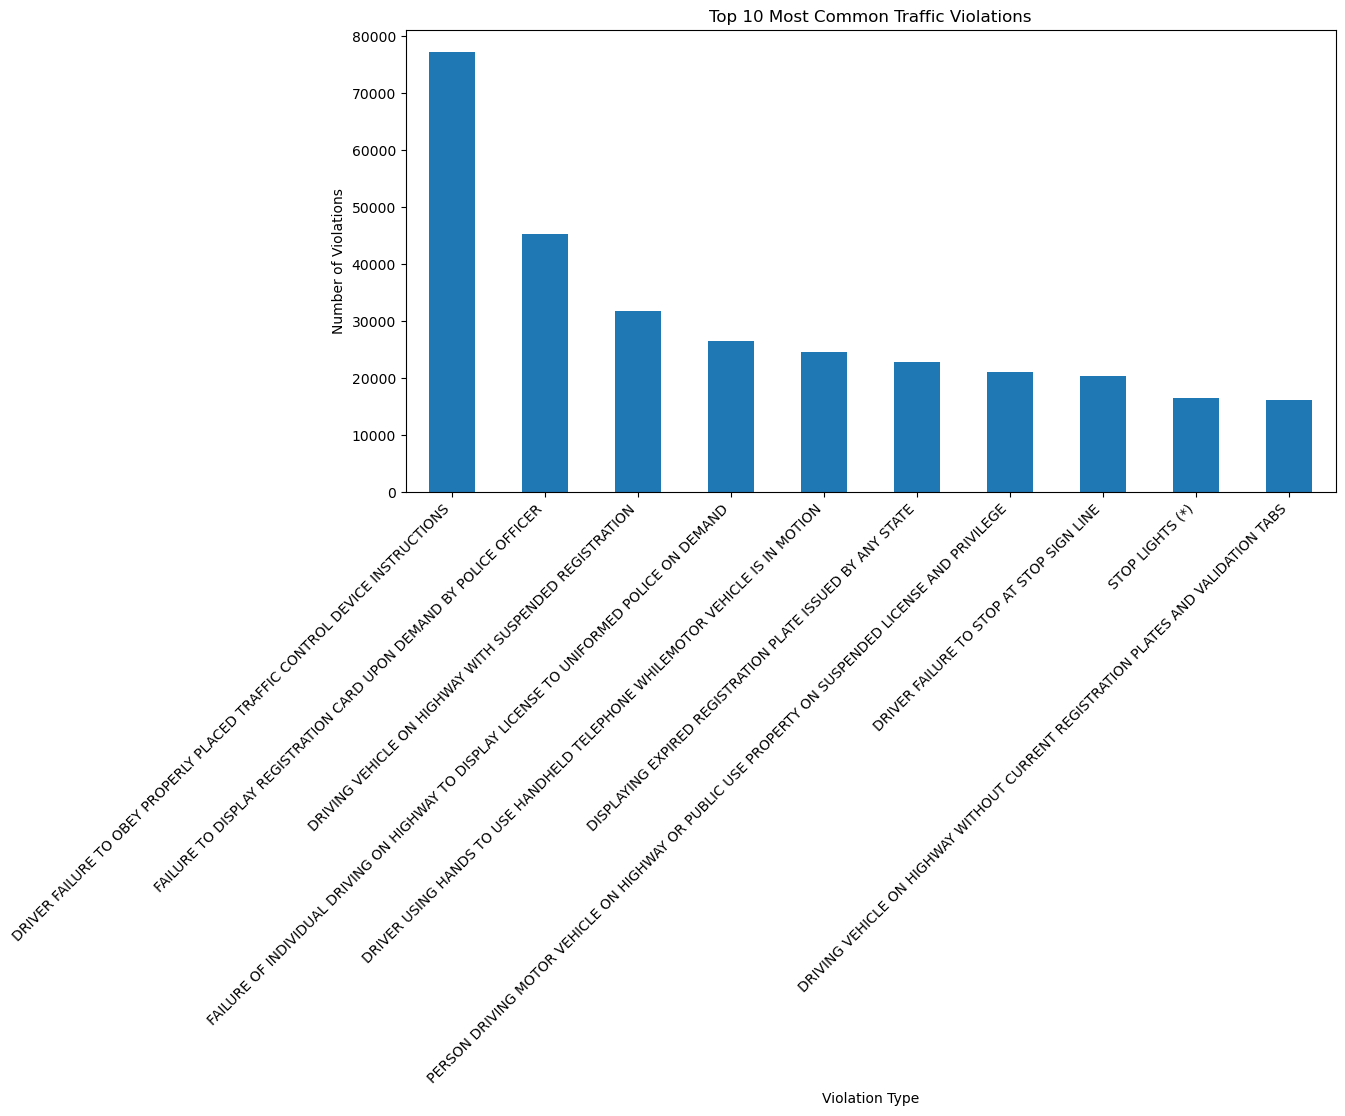

In [38]:
# top 10 common violations

violation_counts = df['Description'].value_counts()

violation_counts.head(10).plot(
    kind = "bar",
    figsize = (12,6)
)
plt.title("Top 10 Most Common Traffic Violations")
plt.xlabel("Violation Type")
plt.ylabel("Number of Violations")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

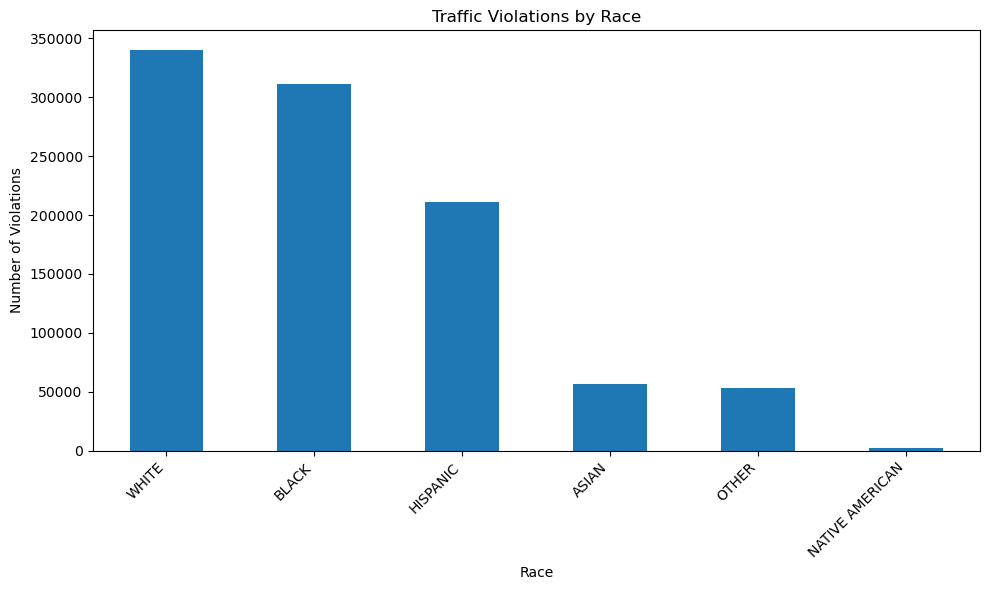

In [46]:
race_counts = df["Race"].value_counts()

race_counts.plot(kind="bar", figsize=(10, 6))

plt.title("Traffic Violations by Race")
plt.xlabel("Race")
plt.ylabel("Number of Violations")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

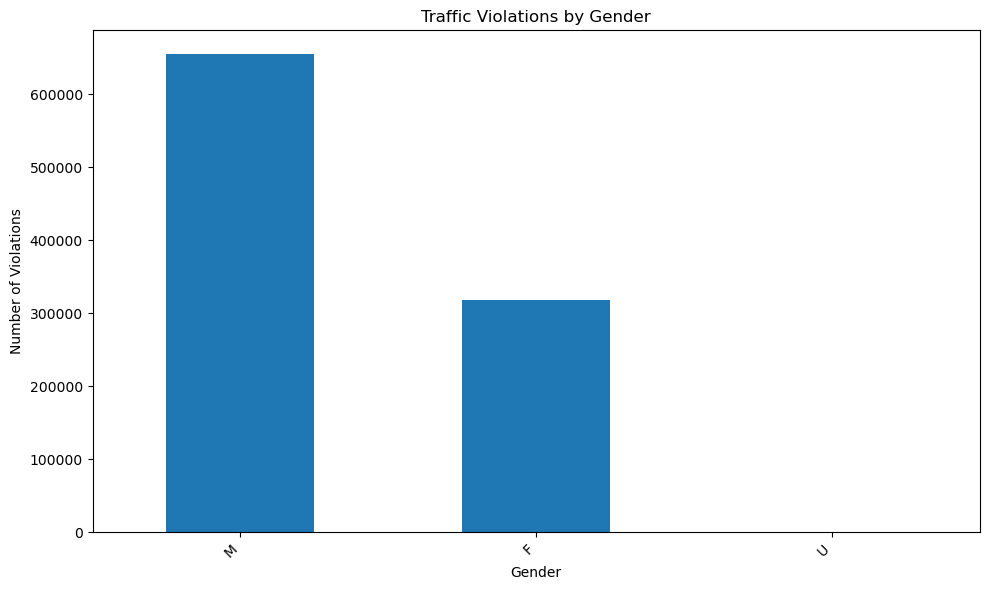

In [48]:
gender_counts = df["Gender"].value_counts()

gender_counts.plot(kind="bar", figsize=(10, 6))

plt.title("Traffic Violations by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Violations")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

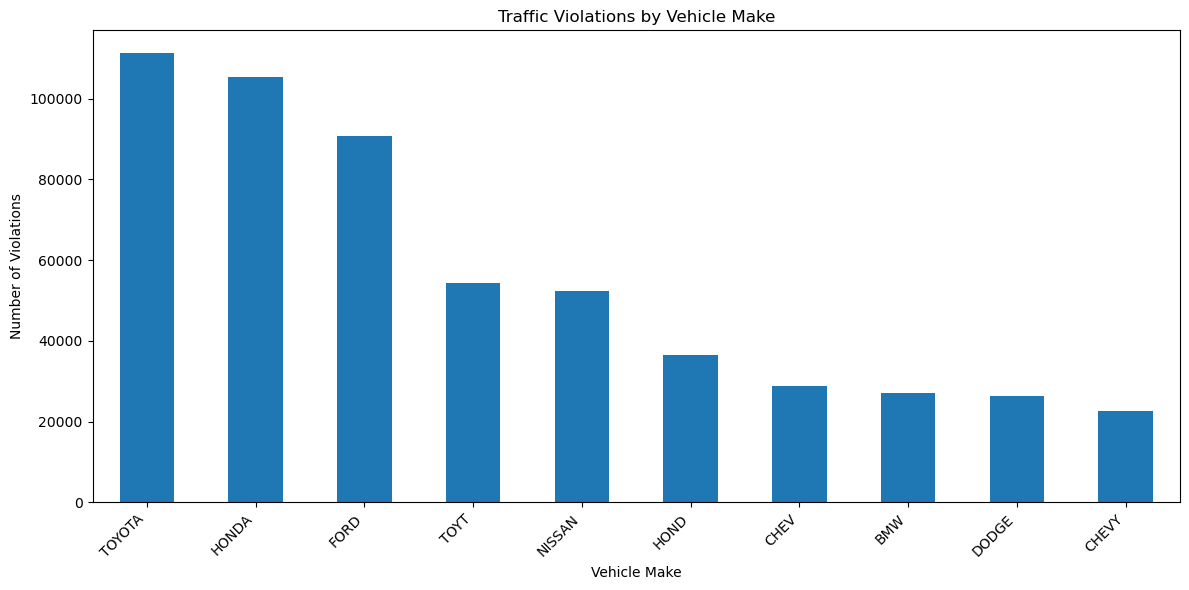

In [62]:
make_counts = df["Make"].value_counts()

make_counts.head(10).plot(
    kind = "bar",
    figsize = (12,6)
)

plt.title("Traffic Violations by Vehicle Make")
plt.xlabel("Vehicle Make")
plt.ylabel("Number of Violations")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

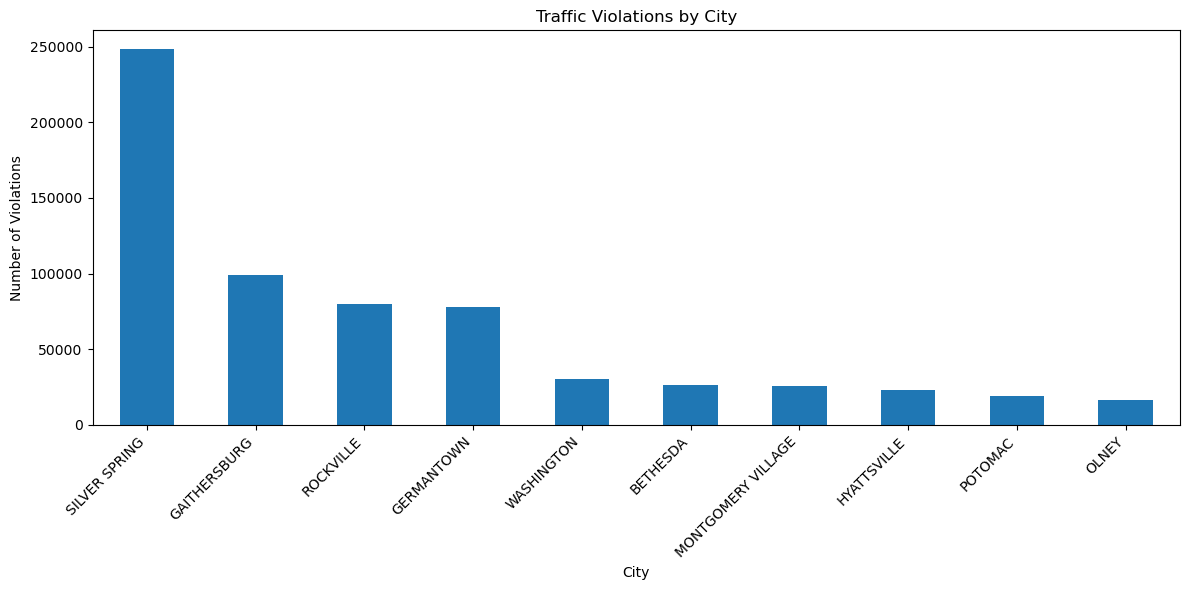

In [81]:
city_counts = df["Driver City"].value_counts()

city_counts.head(10).plot(
    kind = "bar",
    figsize = (12,6)
)

plt.title("Traffic Violations by City")
plt.xlabel("City")
plt.ylabel("Number of Violations")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()